In [1]:
import matplotlib.pyplot as plt


def plot_feature_maps(feature_maps):
    # plot all feature maps
    col = 8
    row = int(feature_maps.shape[3] / col)
    ix = 1
    plt.figure(figsize=(20, 20))
    for _ in range(row):
        for _ in range(col):
            # specify subplot and turn off axis
            ax = plt.subplot(row, col, ix)
            ax.set_xticks([])
            ax.set_yticks([])
            # plot filter channel in grayscale
            plt.imshow(feature_maps[0, :, :, ix - 1], cmap='gray')
            ix += 1
    # show the figure
    plt.show()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,792 (7.00 KB)

 Trainable params: 1,792 (7.00 KB)

 Non-trainable params: 0 (0.00 B)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step
Feature maps:  (1, 224, 224, 64)


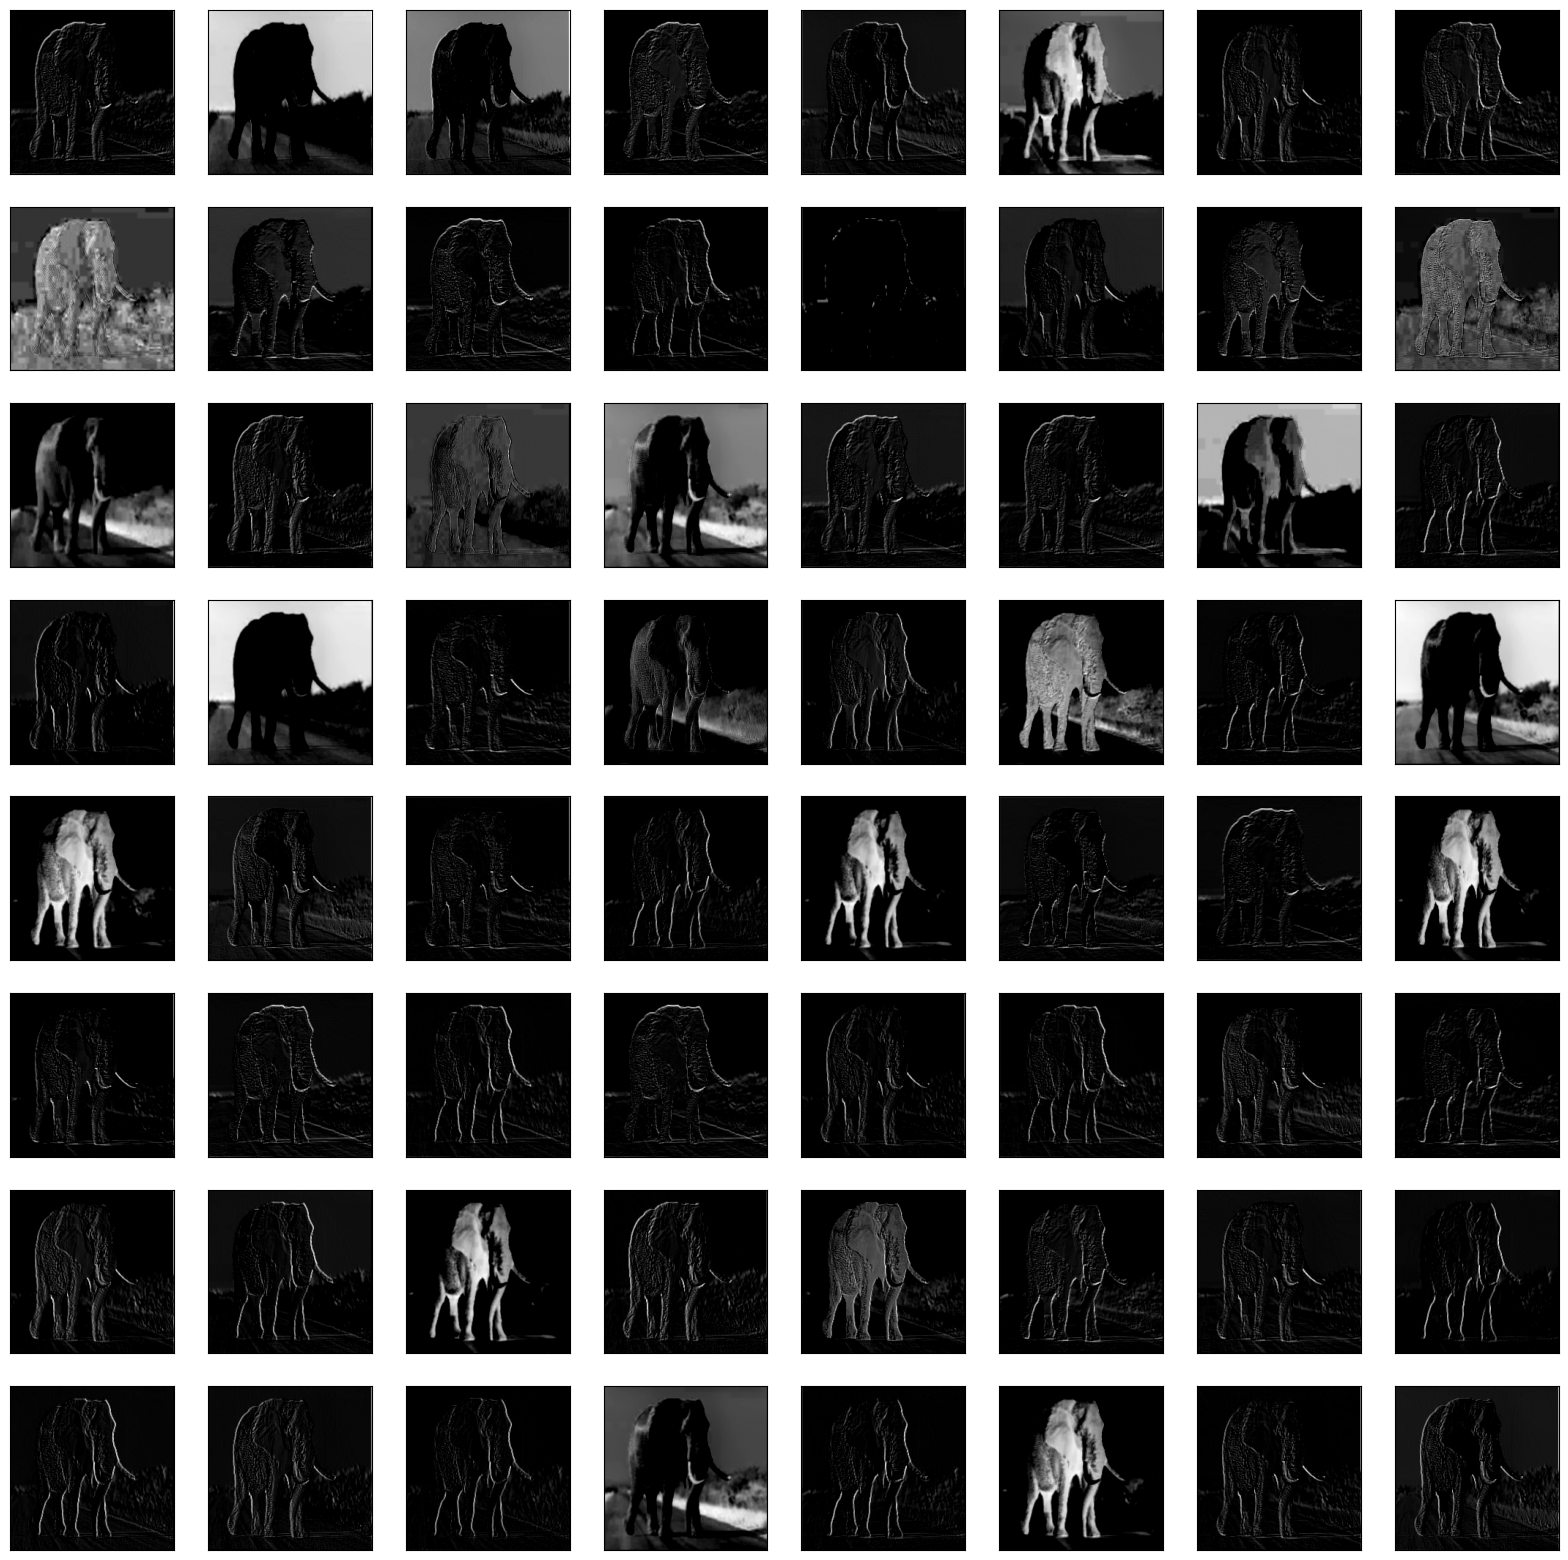

In [4]:
from keras.applications.vgg19 import VGG19
from keras.applications.vgg19 import preprocess_input
from keras.preprocessing.image import load_img
from keras.preprocessing.image import img_to_array
from keras.models import Model
import matplotlib.pyplot as plt
from numpy import expand_dims

# load the model
model = VGG19()
# Select the hidden layer to visualize
n = 1
# redefine model to output right after the hidden layer
model = Model(inputs=model.inputs, outputs=model.layers[n].output)
model.summary()

# load the image with the required shape
img = load_img('Elephant.jpg', target_size=(224, 224))
# convert the image to an array
img = img_to_array(img)
# expand dimensions so that it represents a single sample
img = expand_dims(img, axis=0)
# prepare the image (e.g. scale pixel values for the vgg)
img = preprocess_input(img)
# get feature map for first hidden layer
feature_maps = model.predict(img)
print("Feature maps: ", feature_maps.shape)
# plot all the feature maps
plot_feature_maps(feature_maps)